<a href="https://colab.research.google.com/github/homiecal/dap-playground/blob/master/multiple-disease-impact-on-interpretability-VLM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Multiple disease impact on interpretability VLM**


In [5]:
import torch
print(torch.cuda.is_available())


True


# Setup

Load the CLIP architecture from Chefer library (Transformer-MM-Explainability), then load the ChexZero model weights.

The ChexZero model checkpoint weights can be downloaded from [here](https://drive.google.com/drive/folders/1makFLiEMbSleYltaRxw81aBhEDMpVwno?usp=sharing) otherwise revisit the [README.md](https://github.com/rajpurkarlab/CheXzero/tree/main) from the repository.

In [6]:
!git clone https://github.com/hila-chefer/Transformer-MM-Explainability

# import os
# os.chdir(f'./Transformer-MM-Explainability')

!pip install -q einops ftfy captum

fatal: destination path 'Transformer-MM-Explainability' already exists and is not an empty directory.


In [7]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
!git clone https://github.com/rajpurkarlab/CheXzero.git

fatal: destination path 'CheXzero' already exists and is not an empty directory.


In [9]:
%%capture
import warnings
warnings.filterwarnings("ignore")

# Ignore non-issue warnings with builds for CheXzero
!pip install -q -r CheXzero/requirements.txt

In [10]:
%%capture
!pip -q install h5py torchio clip

In [11]:
import os
os.getcwd()

'/content'

In [12]:
# Import Chefer CLIP function to ensure underlying CLIP structure captures the forward pass attention, and backward pass gradients
import sys

sys.path.insert(0, "/content/Transformer-MM-Explainability")

import CLIP.clip as clip
from CLIP.clip.model import CLIP

print(clip.__file__)

/content/Transformer-MM-Explainability/CLIP/clip/__init__.py


In [13]:
import torch
from PIL import Image
import numpy as np
import cv2
import matplotlib.pyplot as plt
from captum.attr import visualization

if not hasattr(Image, "ANTIALIAS"):
    Image.ANTIALIAS = Image.Resampling.LANCZOS

In [14]:
sys.path.insert(0, "/content/CheXzero")

from CheXzero.data_process import preprocess, img_to_hdf5
from CheXzero.zero_shot import CXRTestDataset

### Load ChezXero weights into CLIP

In [15]:
MODEL_CHECKPOINT = "/content/drive/MyDrive/Research/model-weights/chexzero/best_64_0.0001_original_35000_0.864.pt"

In [16]:
import sys
def load_clip(model_path, pretrained=False, context_length=77):
    """
    FUNCTION: load_clip
    ---------------------------------
    """
    device = "cuda" if torch.cuda.is_available() else "cpu"
    if pretrained is False:
        # use new model params
        params = {
            'embed_dim':512,
            'image_resolution': 224,
            'vision_layers': 12,
            'vision_width': 768,
            'vision_patch_size': 32,
            'context_length': context_length,
            'vocab_size': 49408,
            'transformer_width': 512,
            'transformer_heads': 8,
            'transformer_layers': 12
        }

        model = CLIP(**params)
    else:
        model, preprocess = clip.load("ViT-B/32", device=device, jit=False)
    try:
        model.load_state_dict(torch.load(model_path, map_location=device))
    except:
        print("Argument error. Set pretrained = True.", sys.exc_info()[0])
        raise
    return model


In [17]:
model = load_clip(MODEL_CHECKPOINT, False)

## Intepretability Chefer et. al and Visualisation functions

Copied and adapted from [CLIP-explainability.ipynb](https://github.com/hila-chefer/Transformer-MM-Explainability/blob/main/CLIP_explainability.ipynb).

In [18]:
#@title Control context expansion (number of attention layers to consider)
#@title Number of layers for image Transformer
start_layer =  -1#@param {type:"number"}

#@title Number of layers for text Transformer
start_layer_text =  -1#@param {type:"number"}

In [19]:
def interpret(image, texts, model, device, start_layer=start_layer, start_layer_text=start_layer_text):
    batch_size = texts.shape[0]
    images = image.repeat(batch_size, 1, 1, 1)
    logits_per_image, logits_per_text = model(images, texts)
    probs = logits_per_image.softmax(dim=-1).detach().cpu().numpy()
    index = [i for i in range(batch_size)]
    one_hot = np.zeros((logits_per_image.shape[0], logits_per_image.shape[1]), dtype=np.float32)
    one_hot[torch.arange(logits_per_image.shape[0]), index] = 1
    one_hot = torch.from_numpy(one_hot).requires_grad_(True)
    one_hot = torch.sum(one_hot.cuda() * logits_per_image)
    model.zero_grad()

    image_attn_blocks = list(dict(model.visual.transformer.resblocks.named_children()).values())

    if start_layer == -1:
      # calculate index of last layer
      start_layer = len(image_attn_blocks) - 1

    num_tokens = image_attn_blocks[0].attn_probs.shape[-1]
    R = torch.eye(num_tokens, num_tokens, dtype=image_attn_blocks[0].attn_probs.dtype).to(device)
    R = R.unsqueeze(0).expand(batch_size, num_tokens, num_tokens)
    for i, blk in enumerate(image_attn_blocks):
        if i < start_layer:
          continue
        grad = torch.autograd.grad(one_hot, [blk.attn_probs], retain_graph=True)[0].detach()
        cam = blk.attn_probs.detach()
        cam = cam.reshape(-1, cam.shape[-1], cam.shape[-1])
        grad = grad.reshape(-1, grad.shape[-1], grad.shape[-1])
        cam = grad * cam
        cam = cam.reshape(batch_size, -1, cam.shape[-1], cam.shape[-1])
        cam = cam.clamp(min=0).mean(dim=1)
        R = R + torch.bmm(cam, R)
    image_relevance = R[:, 0, 1:]


    text_attn_blocks = list(dict(model.transformer.resblocks.named_children()).values())

    if start_layer_text == -1:
      # calculate index of last layer
      start_layer_text = len(text_attn_blocks) - 1

    num_tokens = text_attn_blocks[0].attn_probs.shape[-1]
    R_text = torch.eye(num_tokens, num_tokens, dtype=text_attn_blocks[0].attn_probs.dtype).to(device)
    R_text = R_text.unsqueeze(0).expand(batch_size, num_tokens, num_tokens)
    for i, blk in enumerate(text_attn_blocks):
        if i < start_layer_text:
          continue
        grad = torch.autograd.grad(one_hot, [blk.attn_probs], retain_graph=True)[0].detach()
        cam = blk.attn_probs.detach()
        cam = cam.reshape(-1, cam.shape[-1], cam.shape[-1])
        grad = grad.reshape(-1, grad.shape[-1], grad.shape[-1])
        cam = grad * cam
        cam = cam.reshape(batch_size, -1, cam.shape[-1], cam.shape[-1])
        cam = cam.clamp(min=0).mean(dim=1)
        R_text = R_text + torch.bmm(cam, R_text)
    text_relevance = R_text

    return text_relevance, image_relevance

In [108]:
def show_image_relevance(image_relevance, image, orig_image, bboxes=None, ax=None):
    def show_cam_on_image(img, mask):
        heatmap = cv2.applyColorMap(np.uint8(255 * mask), cv2.COLORMAP_JET)
        heatmap = np.float32(heatmap) / 255
        cam = heatmap + np.float32(img)
        return cam / np.max(cam)

    dim = int(image_relevance.numel() ** 0.5)
    image_relevance = image_relevance.reshape(1, 1, dim, dim)
    image_relevance = torch.nn.functional.interpolate(
        image_relevance,
        size=(image.shape[-2], image.shape[-1]),
        mode="bilinear",
    )
    image_relevance = image_relevance.reshape(
        image.shape[-2], image.shape[-1]
    ).detach().cpu().numpy()
    relevance_min, relevance_max = image_relevance.min(), image_relevance.max()
    image_relevance = (image_relevance - relevance_min) / (relevance_max - relevance_min)

    image_np = image[0].permute(1, 2, 0).detach().cpu().numpy()
    image_np = (image_np - image_np.min()) / (image_np.max() - image_np.min())
    vis = show_cam_on_image(image_np, image_relevance)
    vis = np.uint8(255 * vis)
    vis = cv2.cvtColor(vis, cv2.COLOR_RGB2BGR)

    if ax is not None:
        ax.imshow(vis)
        ax.axis("off")
        return

    num_subplots = 2 if bboxes is None else 3
    _, axs = plt.subplots(1, num_subplots)

    axs[0].imshow(orig_image)
    axs[0].set_title("Original Image")
    axs[0].axis("off")

    axs[1].imshow(vis)
    axs[1].set_title("Interpretability Map")
    axs[1].axis("off")

    if bboxes is not None:
        axs[2].imshow(orig_image)
        axs[2].set_title("Ground Truth")
        axs[2].axis("off")
        orig_w, orig_h = orig_image.size

        for bbox in bboxes:
            x1, y1, x2, y2 = bbox
            rect = plt.Rectangle(
                (x1 * orig_w, y1 * orig_h),
                (x2 - x1) * orig_w,
                (y2 - y1) * orig_h,
                fill=False,
                linewidth=2,
            )
            axs[2].add_patch(rect)

In [21]:
from CLIP.clip.simple_tokenizer import SimpleTokenizer as _Tokenizer
_tokenizer = _Tokenizer()

def show_heatmap_on_text(text, text_encoding, R_text):
  CLS_idx = text_encoding.argmax(dim=-1)
  R_text = R_text[CLS_idx, 1:CLS_idx]
  text_scores = R_text / R_text.sum()
  text_scores = text_scores.flatten()
  print(text_scores)
  text_tokens=_tokenizer.encode(text)
  text_tokens_decoded=[_tokenizer.decode([a]) for a in text_tokens]
  vis_data_records = [visualization.VisualizationDataRecord(text_scores,0,0,0,0,0,text_tokens_decoded,1)]
  visualization.visualize_text(vis_data_records)

## Transform and Visualisation functions


In [22]:
device = "cuda" if torch.cuda.is_available() else "cpu"
model = model.to(device)

In [23]:

class color:
   PURPLE = '\033[95m'
   CYAN = '\033[96m'
   DARKCYAN = '\033[36m'
   BLUE = '\033[94m'
   GREEN = '\033[92m'
   YELLOW = '\033[93m'
   RED = '\033[91m'
   BOLD = '\033[1m'
   UNDERLINE = '\033[4m'
   END = '\033[0m'

In [24]:
def get_texts_and_bboxes(image_id, gt_by_image):
  gt_report = gt_by_image[image_id]

  texts = []
  bboxes = []
  for i in gt_report["findings"]:
    texts.append(i['sentence_en'])

    if 'boxes' in i.keys():
      bboxes.append(tuple(box for box in i['boxes']))
    else:
      bboxes.append([])
  return texts, bboxes

In [25]:
def get_texts_and_bboxes_abnormal(image_id, gt_by_image):
  gt_report = gt_by_image[image_id]

  texts = []
  bboxes = []
  for i in gt_report["findings"]:
    if not i['abnormal'] or ('boxes' not in i.keys() or len(i['boxes']) == 0):
      continue
    texts.append(i['sentence_en'])
    bboxes.append(tuple(box for box in i['boxes']))

    # if 'boxes' in i.keys():
    #   bboxes.append(tuple(box for box in i['boxes']))
    # else:
    #   bboxes.append([])
  return texts, bboxes

In [26]:
def get_interpret(image_relevance):
    dim = int(image_relevance.numel() ** 0.5)
    image_relevance = image_relevance.reshape(1, 1, dim, dim)
    image_relevance = torch.nn.functional.interpolate(image_relevance, size=224, mode='bilinear')
    image_relevance = image_relevance.reshape(224, 224).cuda().data.cpu()
    image_relevance = (image_relevance - image_relevance.min()) / (image_relevance.max() - image_relevance.min())
    return image_relevance

In [27]:
def dice_score(image_relevance, bboxes, thresholds):

  image_relevance = get_interpret(image_relevance)
  scores = {}
  for i in thresholds:
    pred = image_relevance > i

    gt_mask = torch.zeros((224, 224), dtype=torch.bool)
    for bbox in bboxes:
      x1, y1, x2, y2 = bbox
      resize_h, resize_w = image_relevance.shape[-2:]
      x1 = round(x1 * resize_w)
      x2 = round(x2 * resize_w)
      y1 = round(y1 * resize_h)
      y2 = round(y2 * resize_h)
      gt_mask[y1:y2, x1:x2] = True

    intersection = (gt_mask & pred).sum()
    dice = (2*intersection / (gt_mask.sum() + pred.sum())).item()
    scores[f"dice_at_{i}"] = dice
  return scores

In [28]:
def bbox_percent(bbox):
  x1, y1, x2, y2 = bbox
  width, length = x2 - x1, y2 - y1
  bboxes_percent_img = length * width
  return bboxes_percent_img

# PadChest-GR

You can download PadChest-GR dataset from https://bimcv.cipf.es/bimcv-projects/padchest/


In [29]:
import json
import glob
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import Compose, Normalize

GROUNDED_REPORTS = "/content/drive/MyDrive/Research/data/padchest-gr/grounded_reports_20240819.json"
with open(
   GROUNDED_REPORTS,
    encoding="utf-8",
) as f:
    gt_by_image = {record["ImageID"]: record for record in json.load(f)}
IMAGE_FOLDER = "/content/drive/MyDrive/Research/data/padchest-gr/PadChest_GR/"
image_paths = glob.glob(f"{IMAGE_FOLDER}/*.png")


In [30]:

# Read image
def read_image(img_path) -> Image.Image:
    img = cv2.imread(str(img_path))
    # convert to PIL Image object
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_pil = Image.fromarray(img)
    return img_pil

# Resize and pad
def preprocess(img, desired_size=320):
    old_size = img.size

    # Here we calculate the ratio between the largest side to the desired size, if the original image
    # is larger than the desired size this number will be between 0 and 1, we then scale the original
    # image down using this ratio, the new_size for the largest side should equal the desired size exactly,
    # with the smaller side being less than the desired size
    ratio = float(desired_size)/max(old_size)
    new_size = tuple([int(x*ratio) for x in old_size])

    # The image is now resized to the new size (maintaing its aspect ratio)
    img = img.resize(new_size, Image.ANTIALIAS)

    # A blank image is created with the desired size, then the resize image is pasted on it, centered, determined by the offset
    # calculated, there will only be 1 offset for either width or height.
    width_offset = (desired_size-new_size[0])//2
    height_offset = (desired_size-new_size[1])//2
    new_img = Image.new('RGB', (desired_size, desired_size))
    new_img.paste(img, (width_offset, height_offset))

    # Return offsets as a percentage, because bounding boxes are given as a ratio of image
    return new_img, (width_offset/desired_size, height_offset/desired_size)

# Transforms 
def to_torch(img_pil: Image.Image) -> torch.Tensor:
    img_arr = np.asarray(img_pil)  # H, W, C
    return torch.from_numpy(img_arr).float().permute(2,0,1) # -> C, H, W


transforms = Compose([
    to_torch,
    Normalize(
        (101.48761,) * 3,
        (83.43944,) * 3
    ),
])


In [31]:
class PadChestDataset(Dataset):
    def __init__(self, image_paths, gt_by_image, transform, abnormal_labels_only = True):

        self.gt_by_image = gt_by_image
        self.transform = transform

        self.abnormal_labels_only = abnormal_labels_only 

        if abnormal_labels_only:
            # Images with abnormal findings and bounding boxes 
            self.samples = [(Path(path), Path(path).name) for path in image_paths if self.image_contains_abnormal_w_labels(self.gt_by_image[Path(path).name])]
        else:
            self.samples = [(Path(path), Path(path).name) for path in image_paths]

        missing = [
            image_id
            for _, image_id in self.samples
            if image_id not in gt_by_image
        ]
        if missing:
            raise ValueError(
                f"Missing annotations for {len(missing)} image(s), "
                f"for example: {missing[:5]}"
            )

    @staticmethod
    def image_contains_abnormal_w_labels(image_findings_id: dict) -> bool:
        for finding in image_findings_id["findings"]:
            if finding["abnormal"] and "boxes" in finding.keys() and finding["boxes"]:
                return True
        return False

    def get_item_by_id(self, image_id):
        for index, (_, id) in enumerate(self.samples):
            if id == image_id:
                return self.__getitem__(index)
        raise ValueError(f"Image ID {image_id} not found in dataset.")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        path, image_id = self.samples[index]

        # Apply the same preprocessing used for your single-image inference.
        # read image using cv2
        img_pil = read_image(str(path))

        # Applly padchest pre processing
        img, (width_offset, height_offset) = preprocess(img_pil, desired_size=224)   

        # Normalise and convert to tensor
        img = transforms(img)

        # Get bboxes and texts for the image
        texts, bboxes = get_texts_and_bboxes_abnormal(
            image_id, self.gt_by_image
        )

        # Adjust bboxes percentages by their offset percentages
        bboxes = [[(x1 + width_offset, y1 + height_offset, x2 + width_offset, y2 + height_offset) for x1, y1, x2, y2 in i] for i in bboxes]

        return image_id, img, texts, bboxes, (width_offset, height_offset)

In [32]:
padchest_abnormal_dataset = PadChestDataset(image_paths, gt_by_image, transforms, True)
padchest_dataset = PadChestDataset(image_paths, gt_by_image, transforms, False)

In [33]:
# Custom collate fn to keep only 1 sample per batch - Chefer interpret template function setup for 1 image so keep it 
# simple given the sample from PadChest-GR is small
def collate_fn_return_one(batch):
    return batch[0]

padchest_abnormal_loader = DataLoader(padchest_abnormal_dataset, batch_size=1, shuffle=False, collate_fn=collate_fn_return_one)

In [ ]:
def show_for_one_image(image_id, model, thresholds = [0.3,0.4,0.5], custom_texts=None, savefig_path=None, show_text_on_plot = True, image_override = None):

    image_id, image, texts, bboxes, offsets = padchest_abnormal_dataset.get_item_by_id(image_id)

    if image_override is not None:
      image = image_override

    image = image.unsqueeze(0).to(device)

    if custom_texts:
       texts = custom_texts

    if texts:
      text = clip.tokenize(texts).to(device)

      R_text, R_image = interpret(model=model, image=image, texts=text, device=device)
      batch_size = text.shape[0]
      dice_results = []
      for i in range(batch_size):
        show_heatmap_on_text(texts[i], text[i], R_text[i])
        show_image_relevance(R_image[i], image, orig_image=Image.open(f"{IMAGE_FOLDER}/{image_id}"), bboxes=bboxes[i])
        # if savefig_path:
        #    plt.savefig()
        plt.show()
        results = dice_score(R_image[i], bboxes[i], thresholds)
        dice_results.append(results)

      print(dice_results)
      # print(image_id)

    return dice_results

In [159]:
import textwrap

def compare_texts_for_image(image_id, model, texts_override=None, image_override=None):
    _, image, texts, bboxes, _ = padchest_abnormal_dataset.get_item_by_id(image_id)

    if texts_override is not None:
        texts = texts_override

    if image_override is not None:
        image = image_override

    image_batch = image.unsqueeze(0).to(device)
    tokens = clip.tokenize(texts).to(device)
    _, R_image = interpret(
        model=model, image=image_batch, texts=tokens, device=device
    )

    original_image = Image.open(f"{IMAGE_FOLDER}/{image_id}")
    _, axes = plt.subplots(
        1, len(texts) + 2,
        figsize=(5 * (len(texts) + 2), 5),
        squeeze=False,
    )
    axes = axes[0]

    input_image = image_batch[0].permute(1, 2, 0).detach().cpu().numpy()
    image_min, image_max = input_image.min(), input_image.max()
    if image_max > image_min:
        input_image = (input_image - image_min) / (image_max - image_min)

    axes[0].imshow(input_image)
    axes[0].set_title("Input image")
    axes[0].axis("off")

    axes[1].imshow(original_image)
    axes[1].set_title("Ground truth")
    axes[1].axis("off")
    orig_w, orig_h = original_image.size

    for finding_boxes in bboxes:
        for x1, y1, x2, y2 in finding_boxes:
            axes[1].add_patch(plt.Rectangle(
                (x1 * orig_w, y1 * orig_h),
                (x2 - x1) * orig_w,
                (y2 - y1) * orig_h,
                fill=False,
                linewidth=2,
            ))

    for i, text in enumerate(texts):
        ax = axes[i + 2]
        show_image_relevance(R_image[i], image_batch, original_image, ax=ax)
        ax.set_title(textwrap.fill(text, width=28), fontsize=12, pad=8)

    plt.tight_layout()
    plt.show()


def compare_texts_for_image_with_gt(image_id, model, image_override=None):
    _, image, texts, bboxes, _ = padchest_abnormal_dataset.get_item_by_id(image_id)
    if len(texts) != len(bboxes):
        raise ValueError(f"Expected one bbox group per text, got {len(bboxes)} bbox groups for {len(texts)} texts")

    if image_override is not None:
        image = image_override

    image_batch = image.unsqueeze(0).to(device)
    tokens = clip.tokenize(texts).to(device)
    _, R_image = interpret(model=model, image=image_batch, texts=tokens, device=device)
    original_image = Image.open(f"{IMAGE_FOLDER}/{image_id}")

    fig = plt.figure(figsize=(5 * (len(texts) + 1), 10))
    grid = fig.add_gridspec(2, len(texts) + 1)

    input_image = image_batch[0].permute(1, 2, 0).detach().cpu().numpy()
    image_min, image_max = input_image.min(), input_image.max()
    if image_max > image_min:
        input_image = (input_image - image_min) / (image_max - image_min)
    input_ax = fig.add_subplot(grid[:, 0])
    input_ax.imshow(input_image)
    input_ax.set_title("Input image", fontsize=12)
    input_ax.axis("off")

    orig_w, orig_h = original_image.size
    for i, text in enumerate(texts):
        heatmap_ax = fig.add_subplot(grid[0, i + 1])
        show_image_relevance(R_image[i], image_batch, original_image, ax=heatmap_ax)
        heatmap_ax.set_title(textwrap.fill(text, width=34), fontsize=14, pad=8)

        gt_ax = fig.add_subplot(grid[1, i + 1])
        gt_ax.imshow(original_image)
        gt_ax.set_title("Ground truth", fontsize=11)
        gt_ax.axis("off")
        for x1, y1, x2, y2 in bboxes[i]:
            gt_ax.add_patch(plt.Rectangle(
                (x1 * orig_w, y1 * orig_h),
                (x2 - x1) * orig_w,
                (y2 - y1) * orig_h,
                fill=False,
                linewidth=2,
            ))

    plt.tight_layout()
    plt.show()

# Examples and results

## Examples (poor localisation for single disease finding)

Example: **101354916913099012081924155376991837012_81ss65.png**
- Has a single disease "**Left** pleural fusion", though interpretability map shows localisation entirely in the **right** lung area, with a dice score of 0 (at thresholds of 0.3, 0.4, 0.5) with the ground truth. This example would likely improve under the DAP method - and is a likely example where BG tokens are associated with the global text token.
- What is interesting, is just how poor the localisation is - it is also interesting (and not necessarily suprising) that the interpretability map does not change much with the change of text, for example referring to morphological descriptions of the disease does not improve the grounding.
- Additionally, the model correctly predicts the original text description very confidently (99% using scaled logits after softmax from ChexZero), despite interpretability map being in the opposite lung with a dice of 0.5.



In [99]:
EXAMPLE_IMAGE_ID = "101354916913099012081924155376991837012_81ss65.png"
image_id, image, texts, bboxes, offsets = padchest_abnormal_dataset.get_item_by_id(EXAMPLE_IMAGE_ID)

In [ ]:
texts.extend(["Right pleural effusion.",
        "Clear lung fields with normal cardiomediastinal contours.",
        "Blunting of the costophrenic angle withc homogeneous fluid opacity, consistent with pleural effusion.",
        "Pneumonia",
        "Clavicle",
        "Neck"])

In [ ]:
import torch.functional as F

text = clip.tokenize(texts).to(device)

batch_size = text.shape[0]
images = image.repeat(batch_size, 1, 1, 1)
images = images.to(device)
# 1. Get image and text embeddings
image_features = model.encode_image(images)
text_features = model.encode_text(text)

# 2. Normalize embeddings to unit length
image_embeddings = F.normalize(image_features, p=2, dim=-1)
text_embeddings = F.normalize(text_features, p=2, dim=-1)

# 3. Cosine similarity matrix: [batch_size, batch_size]
cosine_matrix = image_embeddings @ text_embeddings.T

# Each repeated image is paired with its corresponding text
cosine_similarities = cosine_matrix.diagonal()

# 4. Reproduce CLIP's scaled logits
logit_scale = model.logit_scale.exp()
logits_per_image = logit_scale * cosine_matrix
paired_logits = logits_per_image.diagonal()

In [ ]:
(paired_logits.exp() / paired_logits.exp().sum()) 

tensor([9.9531e-01, 1.8043e-03, 1.4005e-05, 8.6400e-06, 2.8627e-03],
       device='cuda:0', grad_fn=<DivBackward0>)

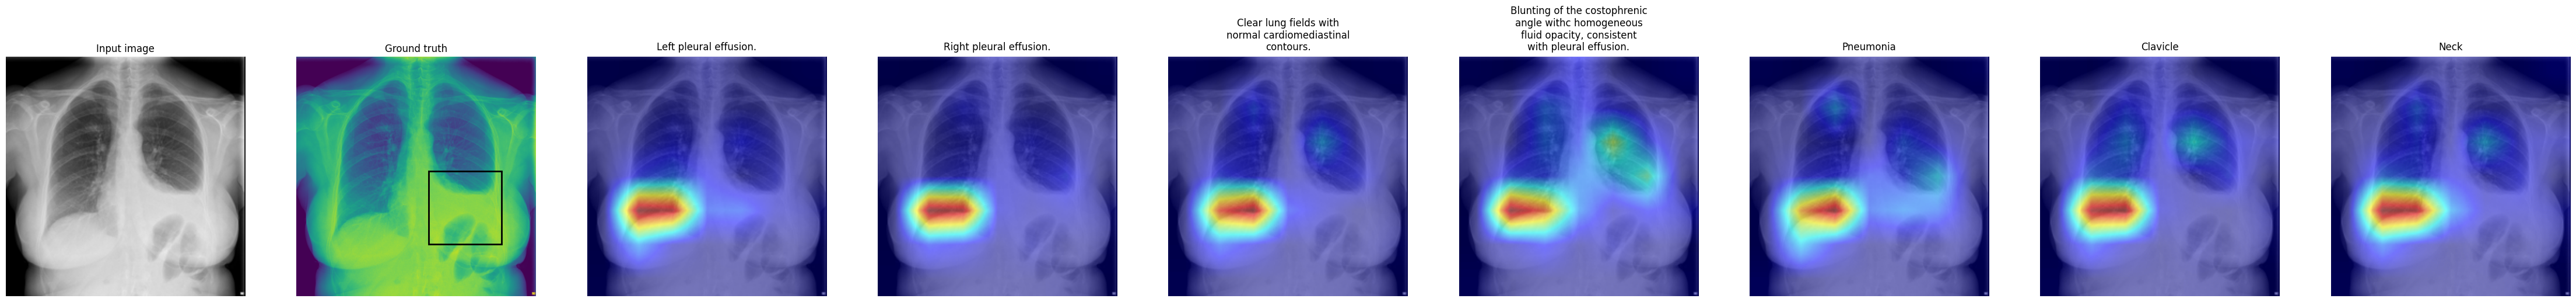

In [166]:
compare_texts_for_image(
    EXAMPLE_IMAGE_ID,
    model,
    [
        "Left pleural effusion.", # Ground truth
        "Right pleural effusion.",
        "Clear lung fields with normal cardiomediastinal contours.",
        "Blunting of the costophrenic angle withc homogeneous fluid opacity, consistent with pleural effusion.",
        "Pneumonia",
        "Clavicle",
        "Neck",
    ],
    # image_override=masked_image,
)

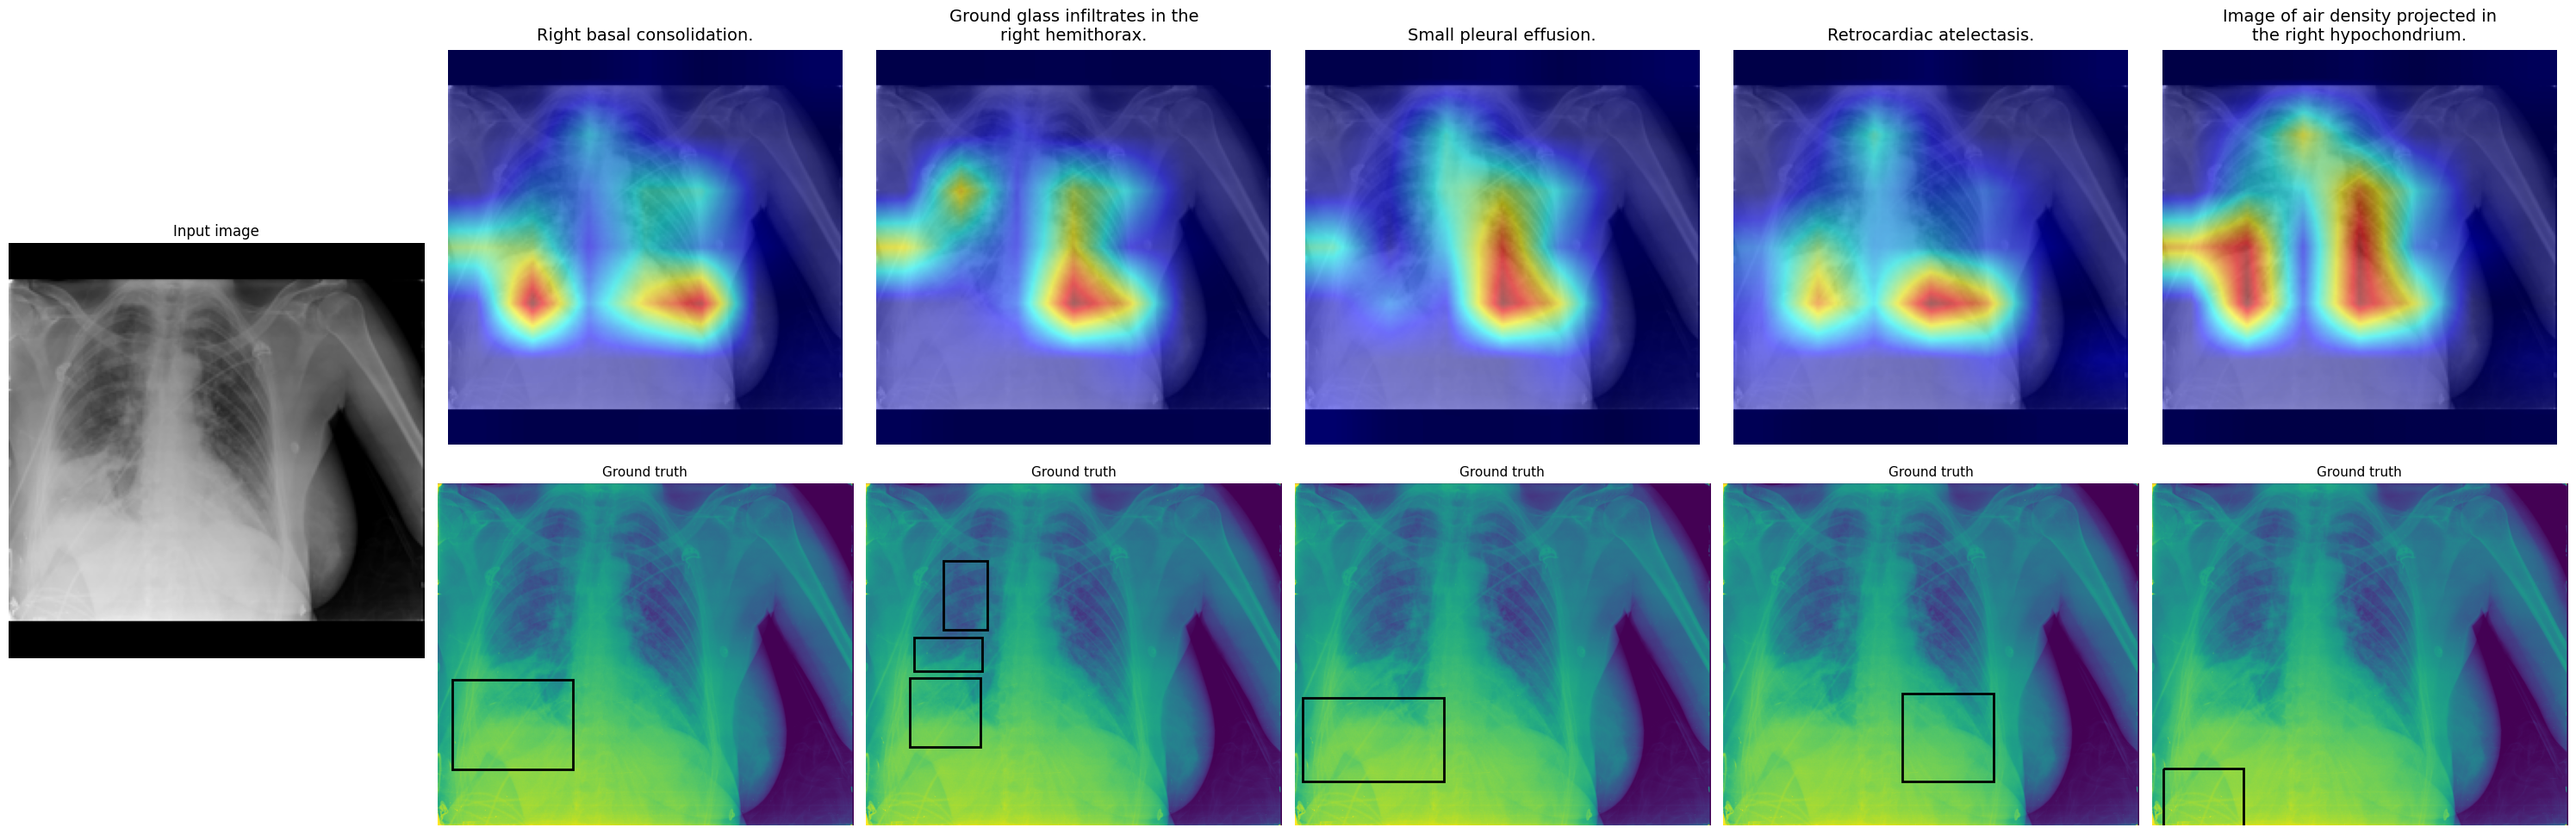

In [160]:
compare_texts_for_image_with_gt(
    "101126299944644944835561376898203180176_2_o5vjuy.png",
    model)

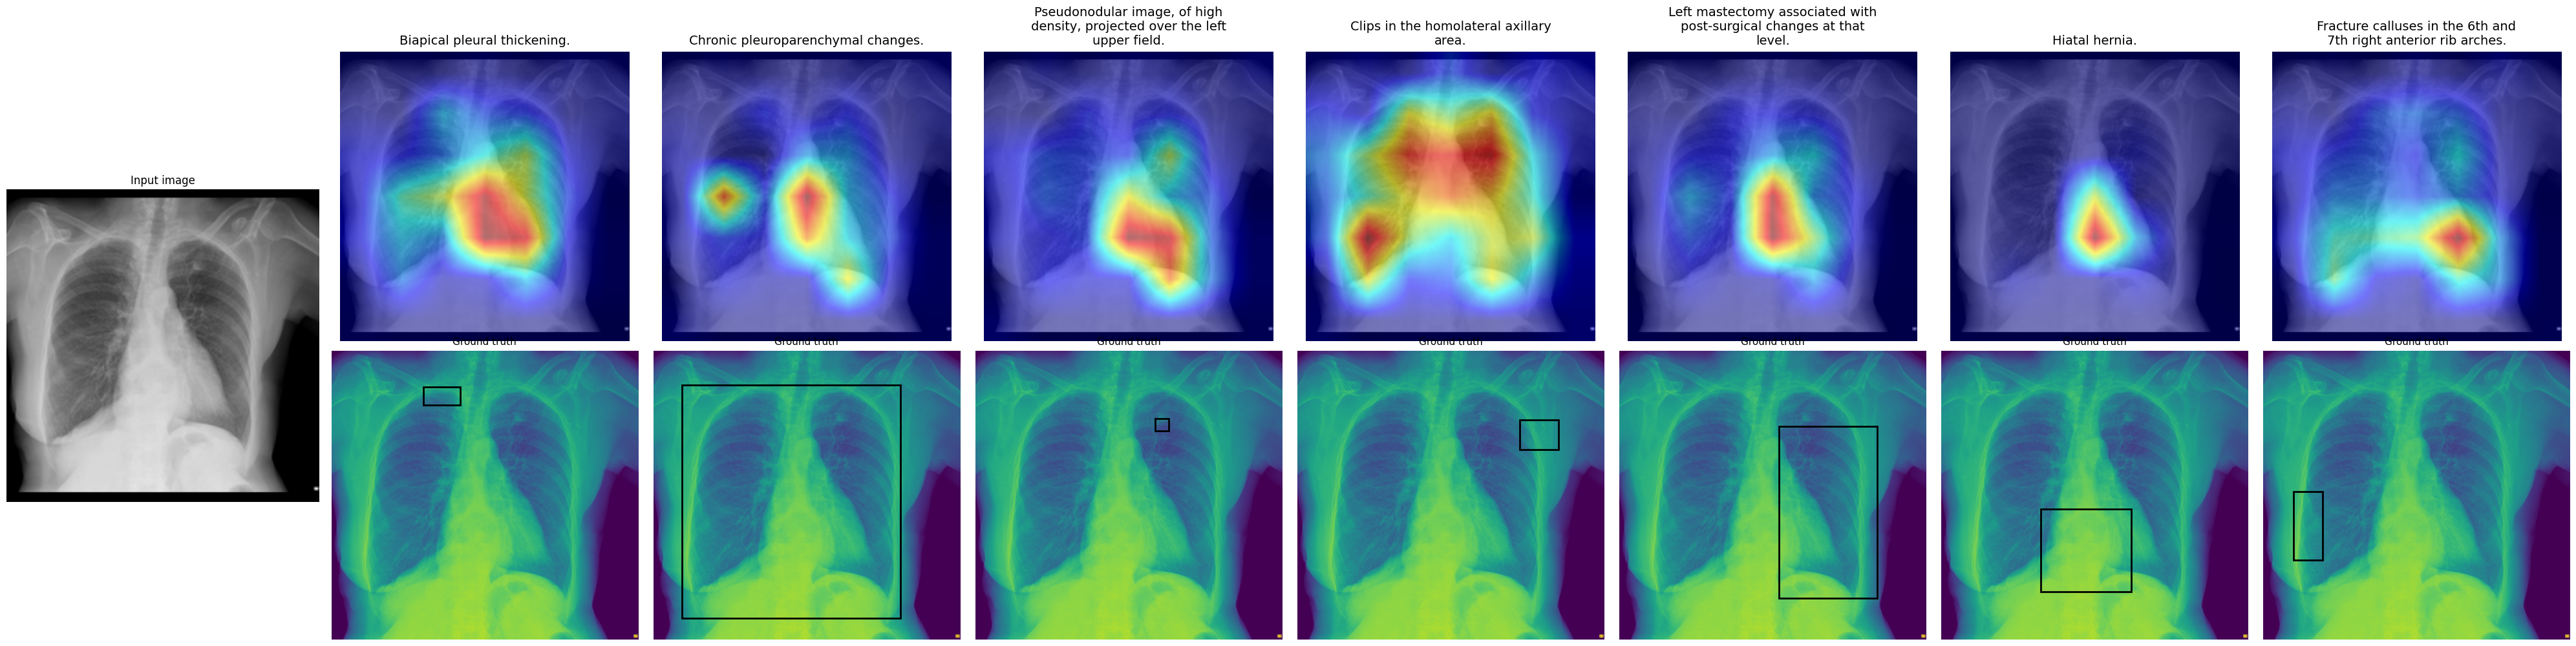

In [161]:
compare_texts_for_image_with_gt(
    "101120174235725780234709445792984239056_2oib6d.png",
    model)

## Dice scores for Chefer interpretability method

In [130]:
import pandas as pd
dice_results_path = "/content/drive/MyDrive/Research/data/padchest-gr/dice_results.json"
dice_results_flag = os.path.exists(dice_results_path)
if dice_results_flag:
    with open(dice_results_path,"r") as f:
        dice_results = json.loads(json.load(f))

In [139]:
df = pd.DataFrame(dice_results)

In [143]:
thresholds = [0.3,0.4,0.5]

# Move the model to the GPU if it's not already there
model = model.to(device)

if not dice_results_flag:
  dice_results = []
  for n, (image_id, image, texts, bboxes, offsets) in enumerate(padchest_abnormal_loader):
      image = image.unsqueeze(0).to(device)

      num_findings_in_image = len(texts)
      if texts:
        text = clip.tokenize(texts).to(device)

        R_text, R_image = interpret(model=model, image=image, texts=text, device=device)
        batch_size = text.shape[0]
        for i in range(batch_size):
          # show_heatmap_on_text(texts[i], text[i], R_text[i])
          # show_image_relevance(R_image[i], image, orig_image=Image.open(f"{IMAGE_FOLDER}/{image_id}"), bboxes=bboxes[i])
          # plt.show()        
          results = dice_score(R_image[i], bboxes[i], thresholds)
          results['no_findings_in_image'] = num_findings_in_image
          results['bbox_percent'] = sum(bbox_percent(bbox) for bbox in bboxes[i])
          results["image_id"] = image_id
          dice_results.append(results)


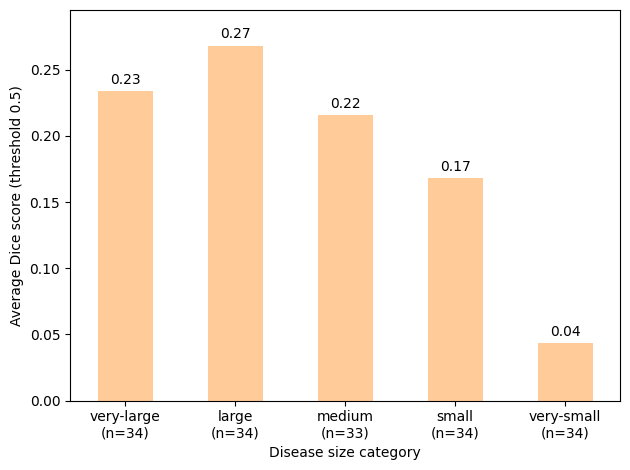

In [144]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.DataFrame(dice_results)

labels = ["very-small", "small", "medium", "large", "very-large"]
reorder = ["very-large", "large", "medium", "small", "very-small"]

df["bbox_category"] = pd.qcut(
    df["bbox_percent"],
    # bins=[-float("inf"), 0.025, 0.075, 0.125, 0.25, float("inf")],
    q=5,
    labels=labels,
)

grouped = df.groupby("bbox_category", observed=False)["dice_at_0.5"]
mean_dice = grouped.mean().reindex(reorder)
counts = grouped.count().reindex(reorder)

ax = mean_dice.plot(kind="bar", color="#ffcc99")
ax.set_xlabel("Disease size category")
ax.set_ylabel("Average Dice score (threshold 0.5)")
ax.set_xticks(
    range(len(reorder)),
    [f"{category}\n(n={count})" for category, count in zip(reorder, counts)],
    rotation=0,
)
ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)
ax.margins(y=0.1)
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Research/data/padchest-gr/dice_score_0.5_by_disease_size.png")
plt.show()


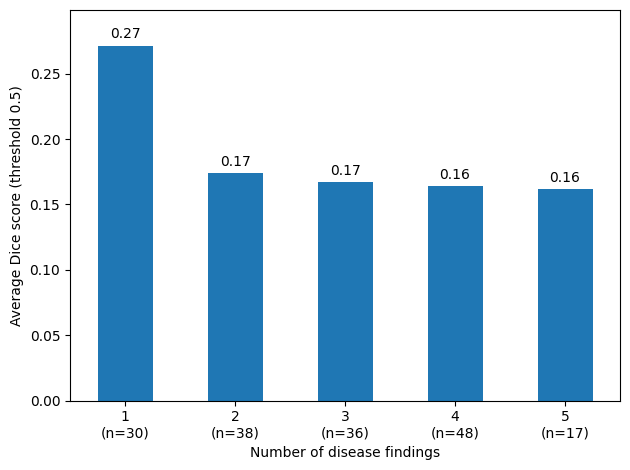

In [145]:
df['no_findings_in_image_cap'] = np.where(df['no_findings_in_image'] > 5, 5,df['no_findings_in_image'])

grouped = df.groupby("no_findings_in_image_cap", observed=False)["dice_at_0.5"]
mean_dice = grouped.mean()
counts = grouped.count()
categories = mean_dice.index

ax = mean_dice.plot(kind="bar")
ax.set_xlabel("Number of disease findings")
ax.set_ylabel("Average Dice score (threshold 0.5)")
ax.set_xticks(
    range(len(categories)),
    [f"{category}\n(n={count})" for category, count in zip(categories, counts)],
    rotation=0
)
ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)
ax.margins(y=0.1)
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Research/data/padchest-gr/dice_score_0.5_by_disease_findings.png")
plt.show()

In [ ]:
with open(dice_results_path,"w") as f:
    json.dump(dice_results, f)

In [151]:
df.sort_values(by=["dice_at_0.5", "no_findings_in_image"], ascending=[True, False])

,dice_at_0.3,dice_at_0.4,dice_at_0.5,no_findings_in_image,bbox_percent,image_id,bbox_category,no_findings_in_image_cap
152,0.000000,0.000000,0.000000,7,0.007394,101120174235725780234709445792984239056_2oib6d...,very-small,5
154,0.000000,0.000000,0.000000,7,0.001875,101120174235725780234709445792984239056_2oib6d...,very-small,5
158,0.045385,0.000000,0.000000,7,0.022277,101120174235725780234709445792984239056_2oib6d...,small,5
33,0.000000,0.000000,0.000000,5,0.082526,101126299944644944835561376898203180176_2_o5vj...,medium,5
35,0.000000,0.000000,0.000000,5,0.048697,101126299944644944835561376898203180176_2_o5vj...,medium,5
...,...,...,...,...,...,...,...,...
0,0.548300,0.599696,0.618302,1,0.085980,102443594909091188793406228640741714201_x3t2lt...,large,1
76,0.733453,0.705631,0.627884,1,0.025890,101393239276161132016124223102217288910-3_lfhq...,small,1
70,0.420137,0.604878,0.631934,2,0.029462,107647298564941375836892227558555493014_irteg2...,small,2
137,0.432432,0.530204,0.634658,4,0.093210,107450329061011888282956449179328678934_1z9e94...,large,4
